Analisis exploratio de los datos del dataset de entrenamiento
Para sabe rpor donde tirar, vamos a hacer 3 cosas:
- Comprobacion del balanceo de clases
- Visualizacion de los cuatro canales para varias muestras de cada clase (ej: 3)
- Limpieza de valores nulos ( NUNCA TIRANDO FILAS, nos cargamos la serie temproal entonces )


Cargamos el dataset como se dice en el readme.md del repo de la competicion (mirar el readme.md nustro)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from competition_api import load_dataset

In [4]:
# 1. Cargar los datos usando la API oficial
print("Cargando datos...")
ds = load_dataset("data/train_100k.npz")
series = ds.series
labels = ds.labels

print(f"Dimensión de las series: {series.shape} -> (Muestras, Canales, Instantes de tiempo)")
print(f"Dimensión de las etiquetas: {labels.shape}\n")

Cargando datos...
Dimensión de las series: (100000, 4, 256) -> (Muestras, Canales, Instantes de tiempo)
Dimensión de las etiquetas: (100000,)



In [12]:
print(series[0, 0, :])  # Imprime la primera serie del primer canal

[ 2.9204006   3.9960284   3.885017    3.000514    2.3231292   1.9971198
  1.4019717   1.5989003   0.0496101  -0.109952    1.4908037   0.55640703
  1.8227183   2.1256664   3.5789719   3.8332384          nan  2.5087502
  2.6129503  -0.51797813 -0.64560163 -0.03136886 -0.04484149  0.96773374
 -1.4004793  -2.7918584  -3.6158745  -1.0302217  -1.126822   -1.126822
 -1.126822   -1.126822   -1.126822   -1.126822   -1.126822   -1.126822
 -1.126822    6.945109    8.569001    6.3243475   6.5762973   5.41346
  4.903584    2.9082153   0.8188851  -0.40607193  0.4455637   1.378107
 -0.5955966  -0.3727059  -1.4735645  -0.9756376  -0.85431486  1.7296382
  1.6137471   2.8102596   4.7184916   4.378737    2.7157223   2.6436405
  2.6199758   3.515233    1.2587643   1.7952025   1.3650056   2.182443
  4.8908587   3.4519236   2.6409736   2.597397    3.6540308   2.4546568
  3.42635     3.427227    4.2316456   3.5057373   3.5869205   2.1610231
  0.39899158  0.6534457   0.33089244 -0.44585156 -0.7210168  -0.4855

Ahora procedemos a hacer el balanceo de clases.

In [5]:
print("--- BALANCE DE CLASES ---")
clases, conteos = np.unique(labels, return_counts=True)
for c, count in zip(clases, conteos):
    porcentaje = (count / len(labels)) * 100
    print(f"Clase {c}: {count} muestras ({porcentaje:.2f}%)")

--- BALANCE DE CLASES ---
Clase 0: 15993 muestras (15.99%)
Clase 1: 14027 muestras (14.03%)
Clase 2: 13937 muestras (13.94%)
Clase 3: 11915 muestras (11.92%)
Clase 4: 11980 muestras (11.98%)
Clase 5: 12160 muestras (12.16%)
Clase 6: 10123 muestras (10.12%)
Clase 7: 9865 muestras (9.87%)


Como podemos observar, ms o menos estan balanceadas, aunque de las 3 primeras hay un poco mas, y de la ultima la que menos, una diferencia del 6% ( no creo q suponga mucho la verdad, si estuvieran muy desbalancedas estariamos realmente jodidos )

Ahora vamos a por los valores nulos. Antes de ver que hacemos con ellos, hacemos un pequeño estudio de si se concentran en algun canal.

In [9]:
nans_por_canal = np.isnan(series).sum(axis=(0, 2))
for i, nans in enumerate(nans_por_canal):
    print(f"Canal {i}: {nans} NaNs")

print("Sumna total de NaNs en todas las series:", np.isnan(series).sum())

Canal 0: 185332 NaNs
Canal 1: 185688 NaNs
Canal 2: 186956 NaNs
Canal 3: 185100 NaNs
Sumna total de NaNs en todas las series: 743076


Hay un total de 743076 valores nulos, y estan practicmanete divididos por igual en las 4 clases. Si bien parecen muchos, no confundirse pues es una matriz tridimensional. Tenemos 100000 muestras, pero en cada muestra, hay 256 lecturas de instantes de tiempo diferentes. Es decir, en total tenemos 25600000 de "datos". Por lo que no hay casi valores nulos. 

Para quitraos, como son -1%, basta con hacer una interpolacion ( recordemos, que como es una serie temporal el orden de las muestras tiene un significado, por lo que si nos falta la muestra 56, podemos hacer la media entre la 55 y la 57 para rellenar es ehueco de en medio)

No manejamos aqui los nulos ( lo idea es una interpolacion ) por si un modelo en concreto necesitase de otra forma de preprocesado.

Ahora vamos con la visualziacion


Generando gráficas...


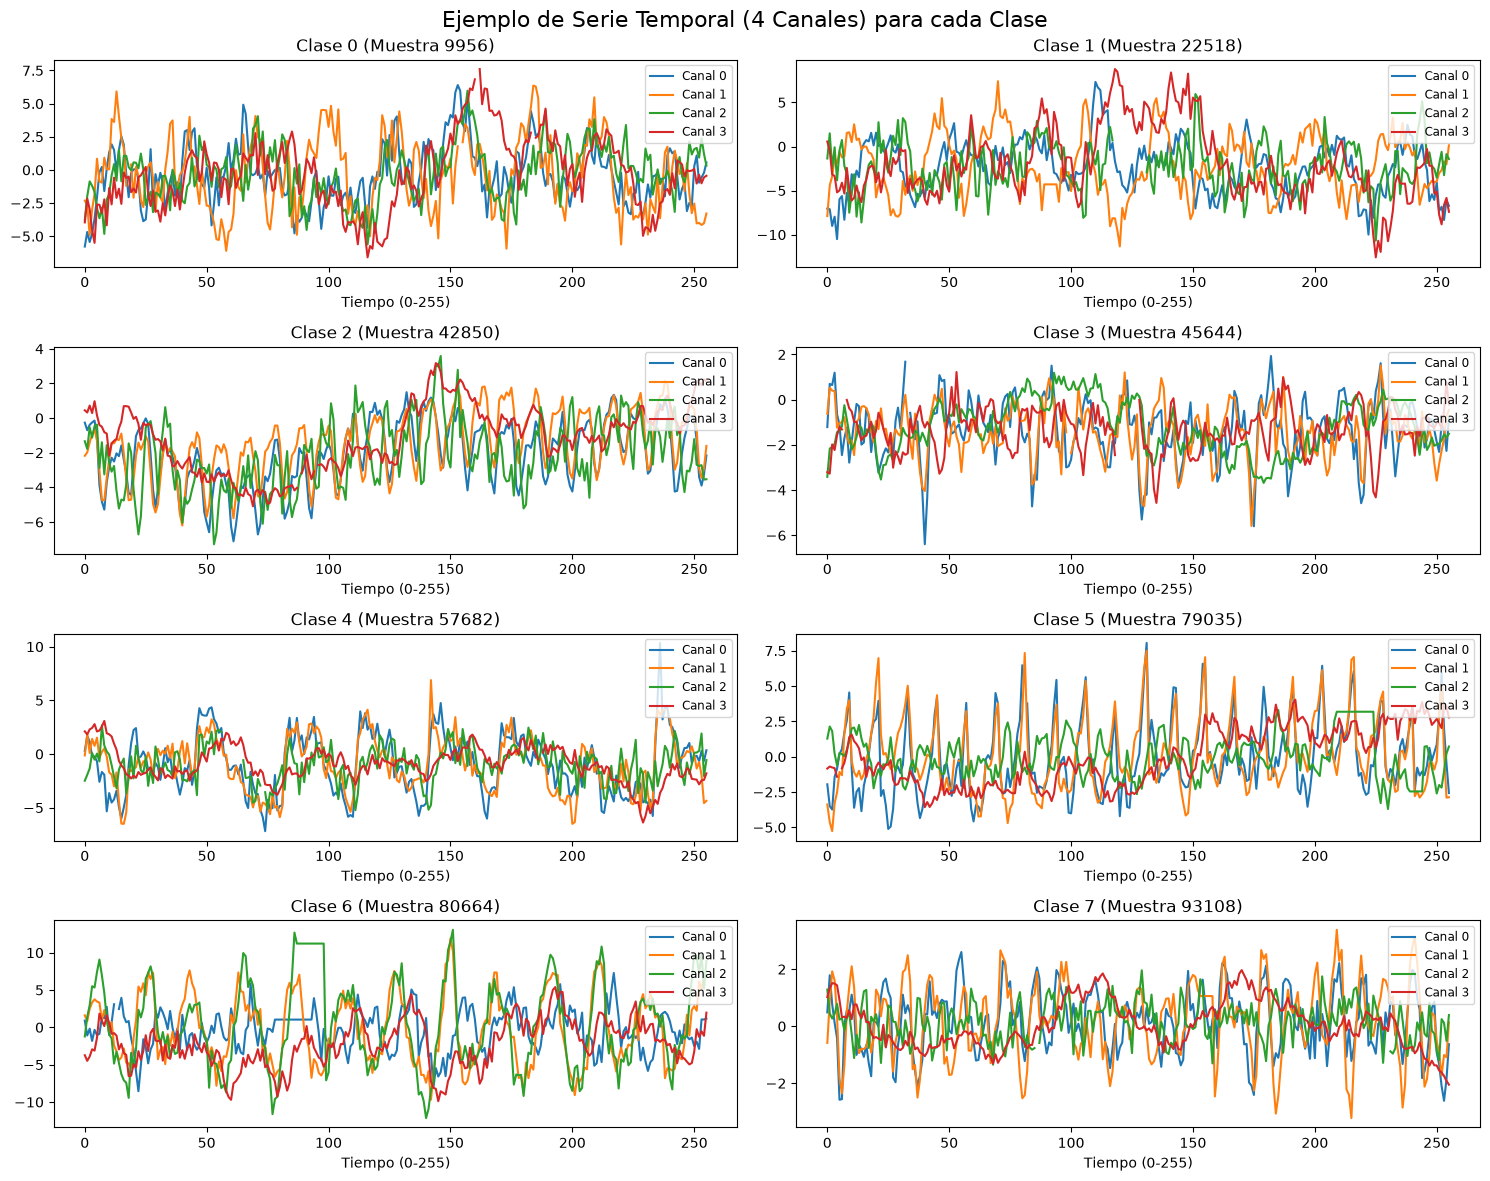

In [13]:
# 4. Visualización de las Series Temporales
print("\nGenerando gráficas...")
fig, axes = plt.subplots(4, 2, figsize=(15, 12))
fig.suptitle('Ejemplo de Serie Temporal (4 Canales) para cada Clase', fontsize=16)

# Dibujar un ejemplo aleatorio para cada una de las 8 clases
for clase_id in range(8):
    # Coger todos los índices que pertenecen a esta clase
    indices_clase = np.where(labels == clase_id)[0]
    # Elegir uno al azar
    idx_aleatorio = np.random.choice(indices_clase)
    muestra = series[idx_aleatorio] # Forma (4, 256)
    
    fila = clase_id // 2
    col = clase_id % 2
    ax = axes[fila, col]
    
    # Dibujar los 4 canales de esa muestra
    for canal in range(4):
        ax.plot(muestra[canal, :], label=f'Canal {canal}')
        
    ax.set_title(f'Clase {clase_id} (Muestra {idx_aleatorio})')
    ax.set_xlabel('Tiempo (0-255)')
    ax.legend(loc='upper right', fontsize='small')

plt.tight_layout()
plt.show()